In [ ]:
%pip install tensorflow numpy matplotlib scikit-learn pillow streamlit

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import PIL
import streamlit as st

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0


#### Import the libraries

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully")

Libraries imported successfully


#### Set the dataset path

In [7]:
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\prana\Downloads\Chest-Xray-2\chest_xray"
)

print("Folder exists:", PROJECT_DIR.exists())
print("Dataset path:", PROJECT_DIR)

Folder exists: True
Dataset path: C:\Users\prana\Downloads\Chest-Xray-2\chest_xray


#### Inspect the extracted files

In [8]:
for path in list(PROJECT_DIR.rglob("*"))[:80]:
    if path.is_dir():
        print("FOLDER:", path)
    elif path.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp"
    }:
        print("IMAGE:", path)

FOLDER: C:\Users\prana\Downloads\Chest-Xray-2\chest_xray\test
FOLDER: C:\Users\prana\Downloads\Chest-Xray-2\chest_xray\train
FOLDER: C:\Users\prana\Downloads\Chest-Xray-2\chest_xray\val
FOLDER: C:\Users\prana\Downloads\Chest-Xray-2\chest_xray\test\NORMAL
FOLDER: C:\Users\prana\Downloads\Chest-Xray-2\chest_xray\test\PNEUMONIA
FOLDER: C:\Users\prana\Downloads\Chest-Xray-2\chest_xray\train\NORMAL
FOLDER: C:\Users\prana\Downloads\Chest-Xray-2\chest_xray\train\PNEUMONIA
FOLDER: C:\Users\prana\Downloads\Chest-Xray-2\chest_xray\val\NORMAL
FOLDER: C:\Users\prana\Downloads\Chest-Xray-2\chest_xray\val\PNEUMONIA
IMAGE: C:\Users\prana\Downloads\Chest-Xray-2\chest_xray\val\NORMAL\NORMAL2-IM-1427-0001.jpeg
IMAGE: C:\Users\prana\Downloads\Chest-Xray-2\chest_xray\val\NORMAL\NORMAL2-IM-1430-0001.jpeg
IMAGE: C:\Users\prana\Downloads\Chest-Xray-2\chest_xray\val\NORMAL\NORMAL2-IM-1431-0001.jpeg
IMAGE: C:\Users\prana\Downloads\Chest-Xray-2\chest_xray\val\NORMAL\NORMAL2-IM-1436-0001.jpeg
IMAGE: C:\Users\pra

#### Find the correct image folders

In [12]:
from pathlib import Path

DATA_DIR = Path(r"C:\Users\prana\Downloads\Chest-Xray-2")

for item in DATA_DIR.iterdir():
    print("Folder:" if item.is_dir() else "File:", item.name)

Folder: chest_xray


#### Set the correct dataset path

In [13]:
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\prana\Downloads\Chest-Xray-2\chest_xray"
)

print("Dataset exists:", DATA_DIR.exists())

for item in DATA_DIR.iterdir():
    if item.is_dir():
        print("Folder:", item.name)

Dataset exists: True
Folder: test
Folder: train
Folder: val


#### Check the image classes

In [14]:
for split in DATA_DIR.iterdir():
    if split.is_dir():
        print(f"\n{split.name}:")
        for class_folder in split.iterdir():
            if class_folder.is_dir():
                print("  ", class_folder.name)


test:
   NORMAL
   PNEUMONIA

train:
   NORMAL
   PNEUMONIA

val:
   NORMAL
   PNEUMONIA


In [16]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

DATA_DIR = Path(r"C:\Users\prana\Downloads\Chest-Xray-2\chest_xray")

print("TensorFlow version:", tf.__version__)
print("Dataset exists:", DATA_DIR.exists())

TensorFlow version: 2.21.0
Dataset exists: True


#### Count the images

In [17]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

for split in ["train", "val", "test"]:
    for category in ["NORMAL", "PNEUMONIA"]:
        folder = DATA_DIR / split / category
        count = sum(
            1 for file in folder.iterdir()
            if file.is_file() and file.suffix.lower() in IMAGE_EXTS
        )
        print(f"{split} - {category}: {count} images")

train - NORMAL: 1341 images
train - PNEUMONIA: 3875 images
val - NORMAL: 8 images
val - PNEUMONIA: 8 images
test - NORMAL: 234 images
test - PNEUMONIA: 390 images


### Load the datasets

#### We'll resize images to 180 × 180 pixels and convert them to grayscale to reduce computation.

In [18]:
IMG_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 42

def load_images(folder, shuffle):
    return keras.utils.image_dataset_from_directory(
        folder,
        class_names=["NORMAL", "PNEUMONIA"],
        image_size=IMG_SIZE,
        color_mode="grayscale",
        batch_size=BATCH_SIZE,
        label_mode="binary",
        shuffle=shuffle,
        seed=SEED
    )

train_ds = load_images(DATA_DIR / "train", True)
val_ds = load_images(DATA_DIR / "val", False)
test_ds = load_images(DATA_DIR / "test", False)

print("Class mapping:", train_ds.class_names)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Class mapping: ['NORMAL', 'PNEUMONIA']


#### Display sample X-ray images

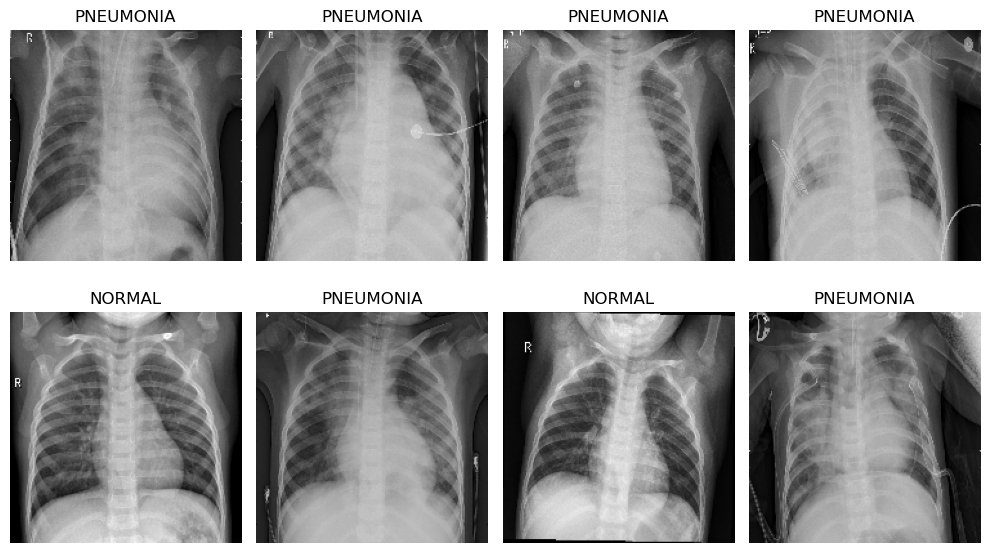

In [19]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 6))

for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().squeeze(), cmap="gray")
    plt.title("PNEUMONIA" if int(labels[i].numpy().squeeze()) == 1 else "NORMAL")
    plt.axis("off")

plt.tight_layout()
plt.show()

#### Prepare the datasets

In [20]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Datasets are ready for training!")

Datasets are ready for training!


#### Build the CNN model
A CNN (Convolutional Neural Network) learns image features to classify X-rays as NORMAL or PNEUMONIA.

In [22]:
model = keras.Sequential([
    layers.Input(shape=(180, 180, 1)),

    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)              │ (None, 180, 180, 1)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 178, 178, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 89, 89, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 87, 87, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 43, 43, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 41, 41, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 20, 20, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 51200)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       6,553,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,646,529 (25.35 MB)

 Trainable params: 6,646,529 (25.35 MB)

 Non-trainable params: 0 (0.00 B)

#### Train the CNN model

In [24]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "pneumonia_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 110s 674ms/step - accuracy: 0.9843 - loss: 0.0389 - precision: 0.9904 - recall: 0.9884 - val_accuracy: 0.8750 - val_loss: 0.1783 - val_precision: 0.8000 - val_recall: 1.0000
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 110s 674ms/step - accuracy: 0.9864 - loss: 0.0319 - precision: 0.9912 - recall: 0.9905 - val_accuracy: 0.6875 - val_loss: 0.6102 - val_precision: 0.6154 - val_recall: 1.0000
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 102s 622ms/step - accuracy: 0.9895 - loss: 0.0261 - precision: 0.9928 - recall: 0.9930 - val_accuracy: 1.0000 - val_loss: 0.0776 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 146s 644ms/step - accuracy: 0.9887 - loss: 0.0334 - precision: 0.9915 - recall: 0.9933 - val_accuracy: 0.8125 - val_loss: 0.3349 - val_precision: 0.7273 - val_recall: 1.0000
Epoch 5/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 106s 648ms/step - accuracy: 0.9864 - loss: 0.0335 - precision: 0.9912 - recall: 0.9905 - val_accuracy: 0

#### Plot training accuracy and loss

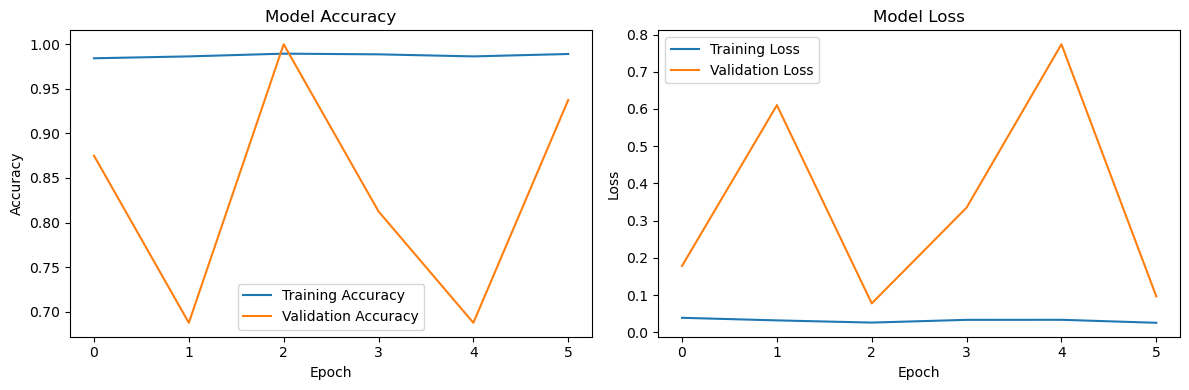

In [25]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

#### Evaluate the model on test images

In [26]:
best_model = keras.models.load_model("pneumonia_model.keras")

test_results = best_model.evaluate(test_ds, return_dict=True)

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 210ms/step - accuracy: 0.7628 - loss: 2.0014 - precision: 0.7274 - recall: 0.9923
accuracy: 0.7628
loss: 2.0014
precision: 0.7274
recall: 0.9923


#### Generate the classification report

In [27]:
y_true = np.concatenate([
    labels.numpy().ravel()
    for _, labels in test_ds
]).astype(int)

y_prob = best_model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

              precision    recall  f1-score   support

      NORMAL       0.97      0.38      0.55       234
   PNEUMONIA       0.73      0.99      0.84       390

    accuracy                           0.76       624
   macro avg       0.85      0.69      0.69       624
weighted avg       0.82      0.76      0.73       624



#### Display the confusion matrix

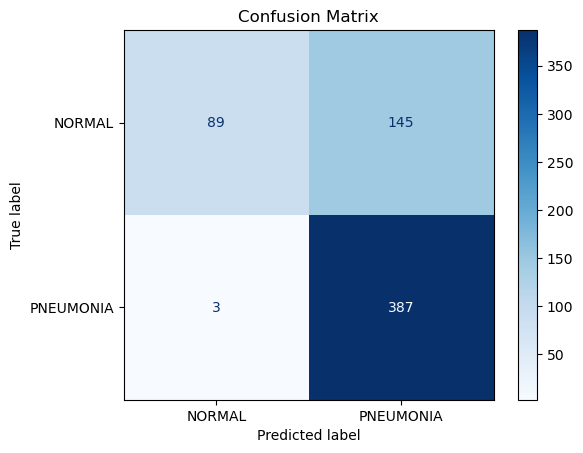

In [28]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [31]:
best_model.save("pneumonia_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [32]:
from pathlib import Path

print(Path("pneumonia_model.keras").resolve())

C:\Users\prana\Project For ML\PRAICP-1012-Pneumonia chest x-ray classification2\pneumonia_model.keras
